<a href="https://colab.research.google.com/github/dldustj0715/machine_learning/blob/main/week06/abalone_deep_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Abalone 딥러닝 실습
Classification (Sex) / Regression (Rings)


## 1. Google Drive 연결 및 데이터 확인

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, mean_absolute_error, mean_squared_error, r2_score

tf.keras.utils.set_random_seed(42)

path = '/content/drive/MyDrive/abalone.csv'
df = pd.read_csv(path)
print(df.shape)
display(df.head())
print(df.isnull().sum())
print(df['Sex'].value_counts())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(4177, 10)


,id,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
0,0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


id                0
Sex               0
Length            0
Diameter          0
Height            0
Whole_weight      0
Shucked_weight    0
Viscera_weight    0
Shell_weight      0
Rings             0
dtype: int64
Sex
M    1528
I    1342
F    1307
Name: count, dtype: int64


## 2. Classification — Sex (M/F/I) 예측
`Sex`를 정답으로 설정한다. 입력에서 `id`, `Sex`를 제외한다. 정답은 원-핫 인코딩하고 출력층에 `softmax`, 손실 함수에 `categorical_crossentropy`를 사용한다.

In [3]:
X_cls = df.drop(columns=['id', 'Sex']).values.astype('float32')
y_cls = df['Sex']
classes = ['F', 'I', 'M']
Y_cls = pd.get_dummies(y_cls).reindex(columns=classes, fill_value=0).values.astype('float32')

print('X:', X_cls.shape, 'Y:', Y_cls.shape)
print('Class order:', classes)
print('One-hot examples:')
display(pd.DataFrame(Y_cls[:5], columns=classes))

X: (4177, 8) Y: (4177, 3)
Class order: ['F', 'I', 'M']
One-hot examples:


,F,I,M
0,0.0,0.0,1.0
1,0.0,0.0,1.0
2,1.0,0.0,0.0
3,0.0,0.0,1.0
4,0.0,1.0,0.0


In [4]:
Xc_train, Xc_test, Yc_train, Yc_test = train_test_split(
    X_cls, Y_cls, test_size=0.2, random_state=42, stratify=y_cls
)
scaler_cls = StandardScaler()
Xc_train = scaler_cls.fit_transform(Xc_train)
Xc_test = scaler_cls.transform(Xc_test)

In [5]:
classification_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(Xc_train.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])
classification_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
classification_model.summary()
history_cls = classification_model.fit(Xc_train, Yc_train, epochs=100, batch_size=32, validation_split=0.2, verbose=1)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 867 (3.39 KB)

 Trainable params: 867 (3.39 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.5198 - loss: 0.9557 - val_accuracy: 0.5127 - val_loss: 0.9449
Epoch 2/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5385 - loss: 0.8719 - val_accuracy: 0.5217 - val_loss: 0.9124
Epoch 3/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5445 - loss: 0.8502 - val_accuracy: 0.5157 - val_loss: 0.9057
Epoch 4/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5618 - loss: 0.8424 - val_accuracy: 0.5247 - val_loss: 0.9034
Epoch 5/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5692 - loss: 0.8378 - val_accuracy: 0.5381 - val_loss: 0.9023
Epoch 6/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5775 - loss: 0.8344 - val_accuracy: 0.5291 - val_loss: 0.9011
Epoch 7/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5812 - loss: 0.8318 - val_accuracy: 0.5351 - val_loss: 0.8999
Epoch 8/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5827 - loss: 0.8293 - val_accuracy: 0.5396 - v

In [6]:
loss_cls, acc_cls = classification_model.evaluate(Xc_test, Yc_test, verbose=0)
print(f'Test Loss: {loss_cls:.4f}')
print(f'Test Accuracy: {acc_cls:.4f}')
probs = classification_model.predict(Xc_test, verbose=0)
pred_cls = np.argmax(probs, axis=1)
true_cls = np.argmax(Yc_test, axis=1)
print(classification_report(true_cls, pred_cls, labels=range(3), target_names=classes, zero_division=0))
print('Confusion matrix:\n', confusion_matrix(true_cls, pred_cls, labels=range(3)))

Test Loss: 0.8440
Test Accuracy: 0.5490
              precision    recall  f1-score   support

           F       0.44      0.39      0.41       261
           I       0.74      0.75      0.74       269
           M       0.47      0.50      0.49       306

    accuracy                           0.55       836
   macro avg       0.55      0.55      0.55       836
weighted avg       0.55      0.55      0.55       836

Confusion matrix:
 [[103  20 138]
 [ 33 203  33]
 [100  53 153]]


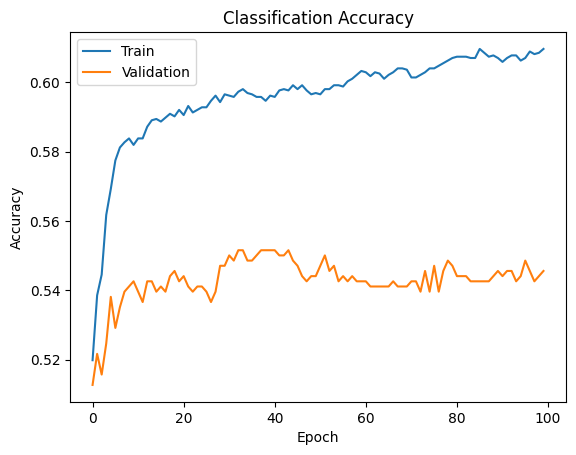

In [7]:
plt.plot(history_cls.history['accuracy'], label='Train')
plt.plot(history_cls.history['val_accuracy'], label='Validation')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.title('Classification Accuracy')
plt.legend(); plt.show()

## 3. Regression — Rings 예측
`Rings`를 정답으로 설정한다. `Sex`는 입력 특성으로 원-핫 인코딩한다. 회귀 출력층에는 활성화 함수를 지정하지 않으며 손실 함수는 `mse`이다.

In [8]:
X_reg_df = pd.get_dummies(df.drop(columns=['id', 'Rings']), columns=['Sex'], dtype=int)
X_reg = X_reg_df.values.astype('float32')
y_reg = df['Rings'].values.astype('float32')
print('Regression input columns:', list(X_reg_df.columns))
print('X:', X_reg.shape, 'y:', y_reg.shape)

Regression input columns: ['Length', 'Diameter', 'Height', 'Whole_weight', 'Shucked_weight', 'Viscera_weight', 'Shell_weight', 'Sex_F', 'Sex_I', 'Sex_M']
X: (4177, 10) y: (4177,)


In [9]:
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)
scaler_reg = StandardScaler()
Xr_train = scaler_reg.fit_transform(Xr_train)
Xr_test = scaler_reg.transform(Xr_test)

In [10]:
regression_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(Xr_train.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1)
])
regression_model.compile(optimizer='adam', loss='mse', metrics=['mae'])
regression_model.summary()
history_reg = regression_model.fit(Xr_train, yr_train, epochs=100, batch_size=32, validation_split=0.2, verbose=1)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 897 (3.50 KB)

 Trainable params: 897 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 75.2032 - mae: 7.7766 - val_loss: 38.3957 - val_mae: 5.3143
Epoch 2/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 22.1049 - mae: 3.5576 - val_loss: 13.3091 - val_mae: 2.7350
Epoch 3/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 11.7265 - mae: 2.3728 - val_loss: 7.7688 - val_mae: 2.0447
Epoch 4/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 8.3991 - mae: 1.9363 - val_loss: 6.0234 - val_mae: 1.7942
Epoch 5/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 7.2643 - mae: 1.8079 - val_loss: 5.4232 - val_mae: 1.7102
Epoch 6/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 6.6580 - mae: 1.7516 - val_loss: 5.0759 - val_mae: 1.6514
Epoch 7/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 6.2331 - mae: 1.7108 - val_loss: 4.8412 - val_mae: 1.6051
Epoch 8/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.9243 - mae: 1.6811 - val_loss: 4.6825 - val_mae: 1.5728
Epoch 9/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 

In [11]:
loss_reg, mae_reg = regression_model.evaluate(Xr_test, yr_test, verbose=0)
y_pred = regression_model.predict(Xr_test, verbose=0).flatten()
print(f'Test MSE: {loss_reg:.4f}')
print(f'Test MAE: {mae_reg:.4f}')
print(f'Test R2: {r2_score(yr_test, y_pred):.4f}')
display(pd.DataFrame({'Actual Rings': yr_test, 'Predicted Rings': y_pred}).head(10))

Test MSE: 4.4146
Test MAE: 1.5119
Test R2: 0.5922


,Actual Rings,Predicted Rings
0,9.0,12.119944
1,8.0,9.562975
2,16.0,15.589199
3,9.0,11.583282
4,14.0,12.231331
5,11.0,10.306189
6,7.0,9.188046
7,6.0,8.388371
8,7.0,6.869637
9,10.0,10.723091


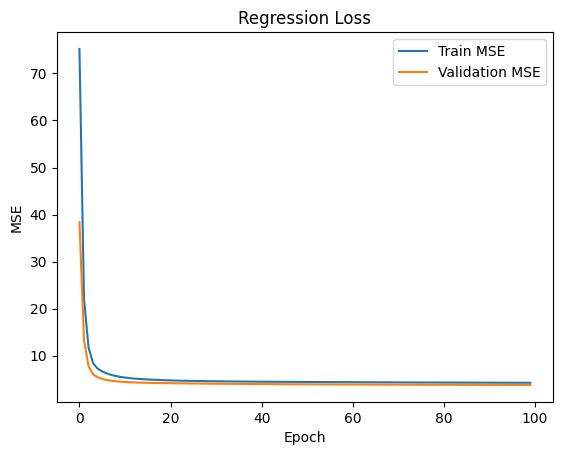

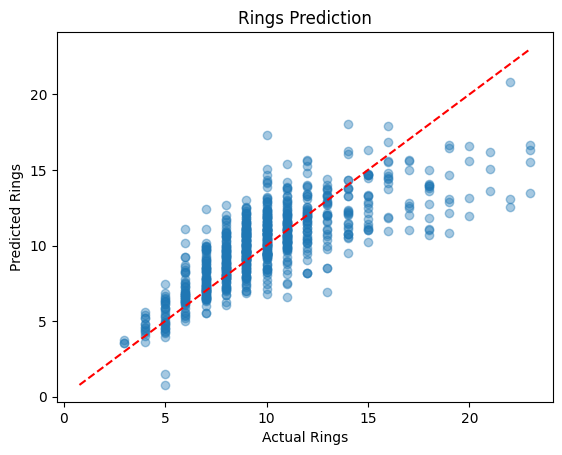

In [12]:
plt.plot(history_reg.history['loss'], label='Train MSE')
plt.plot(history_reg.history['val_loss'], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.title('Regression Loss')
plt.legend(); plt.show()

plt.scatter(yr_test, y_pred, alpha=0.4)
limits = [min(yr_test.min(), y_pred.min()), max(yr_test.max(), y_pred.max())]
plt.plot(limits, limits, 'r--')
plt.xlabel('Actual Rings'); plt.ylabel('Predicted Rings'); plt.title('Rings Prediction')
plt.show()

- **Classification:** 3개 클래스 원-핫 인코딩 → `softmax` + `categorical_crossentropy`
- **Regression:** 고리 수 예측 → 활성화 함수 없음(linear) + `mse`